# Phishing URL Detection
## Importing Data 

In [22]:
# https://pandas.pydata.org/docs/reference/index.html
import pandas as pd

#loads the CSV file and stores it as "df" or Data Frame
df = pd.read_csv("dataset/malicious_phish.csv")
#gives us the size of the table
print(df.shape)
#tells us what data types are in each column
print(df.dtypes)
#counts the missing values if there are any
print(df.isna().sum())
#counts the amount of each value appear in the data
print(df["type"].value_counts())
#shows 10 random rows as an example
df.sample(10)

(651191, 2)
url     object
type    object
dtype: object
url     0
type    0
dtype: int64
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64


,url,type
524028,https://docs.google.com/forms/d/e/1FAIpQLSe5aq...,phishing
58049,http://www.platingroup.az/en/kitabxana,defacement
228795,musicians-home.ning.com/profile/KellyQuinn,benign
424833,kallohonka.fi,phishing
388465,decentfilms.com/reviews/coraline.html,benign
67909,http://www.sezioneanatreviso.it/index.php?opti...,defacement
514939,tvguide.com/celebrities/mark-harmon/164630,benign
348448,indublin.com/,benign
493195,rbr.com/tv-cable/newport-television-sees-core-...,benign
296596,britnisenkiw.com,phishing


## Cleaning Data

In [23]:
#uses "dropna" to get rid of any missing entrys
#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html#
df = df.dropna(subset=["url", "type"])
#turns all values in the URL colomn into strings and then removes spaces, tabs and other stuff so that it make it easier to read
df["url"] = df["url"].astype(str).str.strip()
#creates a column of bool values where True is a URL that has text and False are just blank
df = df[df["url"] != ""]
#counts how many rows are a repeat of a URL that is already in the data
#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html
print("Duplicate URLs found:", df.duplicated(subset=["url"]).sum())
#uses "drop_duplicates" to keep the first copy of each URL and remove the repeats
#this is done so the same URL cant end up in both the training set and the test set
#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html
df = df.drop_duplicates(subset=["url"], keep="first")
#renumbers the rows from 0 so there are no gaps left where the duplicates were removed
df = df.reset_index(drop=True)
print("Rows left after removing duplicates:", df.shape[0])
df.sample(10)

Duplicate URLs found: 10072
Rows left after removing duplicates: 641119


,url,type
98568,it.linkedin.com/in/francescoleoni,benign
129707,eternitytoday.net/,benign
528931,https://spdtextile.com/sport/132Cl2.exe,malware
103857,mytrees.com/stewartgenealogy/STEWART-2159.html,benign
294371,http://www.borg4x4.org/index.php?option=com_co...,defacement
278397,ls3ocnra-site.1tempurl.com,phishing
346546,gayegypt.com/films.html,benign
602060,www.cwc.org/industry/ibp001rpt.pdf,phishing
494239,yellowpages.ca/bus/British-Columbia/Victoria/B...,benign
214420,wordpress.org/extend/plugins/mobify/faq/,benign


In [24]:
#use "map" to assign a int to each type so that it is easier to sort and understand
#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.map.html
df["type"] = df["type"].map({"phishing": 0, "benign": 1, "defacement": 2, "malware": 3})
#cleans out all the rows that arnt in the dictionary above
df = df.dropna(subset=["type"])
#converts all the types to int incase any werent
df["type"] = df["type"].astype(int)

def simple_preprocess(url):
    if pd.isna(url):
        return ""
    #strips the www. off the urls so its easier to read
    url = url.replace('https://', '').replace('http://', '').replace('www.', '')
    return url.lower().strip()

df['clean_url'] = df['url'].apply(simple_preprocess)

#gives me a test sample to see if the map worked
df.sample(10)

,url,type,clean_url
209538,http://onlineigri.net/sejeal.jpg,2,onlineigri.net/sejeal.jpg
226786,http://riedland.ch/index.php?option=com_phocag...,2,riedland.ch/index.php?option=com_phocagallery&...
515630,http://btiesolutions.com/images/logo/page/,0,btiesolutions.com/images/logo/page/
174650,myspace.com/nickasaur,1,myspace.com/nickasaur
366480,http://virginiabeachautobody.com/index.php?opt...,2,virginiabeachautobody.com/index.php?option=com...
300244,dimasds.dagdigdug.com/,1,dimasds.dagdigdug.com/
256472,stoneriver.org/,1,stoneriver.org/
444256,http://www.prosuzdal.ru/index.php/posmotret-v-...,2,prosuzdal.ru/index.php/posmotret-v-suzdale/37-...
325924,mylife.com/c-768440403,1,mylife.com/c-768440403
152816,community.livejournal.com/montreal/2752586.html,1,community.livejournal.com/montreal/2752586.html


## Machine Learning model Random Forest Classifier

In [ ]:
#gets the function that will split the data into the training set and the test set
#https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
from sklearn.model_selection import train_test_split
#
from sklearn.feature_extraction.text import TfidfVectorizer
#gets the Random Forest model that make a collection of decision trees that vote of the best answer
#https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html 
from sklearn.ensemble import RandomForestClassifier

from scipy.sparse import hstack

# Extracting Features

In [26]:
import re
import math
from urllib.parse import urlparse
from collections import Counter
from tqdm import tqdm
#Shannon entropy is a measure of the randomness of the URL
def shannon_entropy(s):
    if not s:
        return 0.0
    counts = Counter(s)
    length = len(s)
    return -sum((c / length) * math.log2(c / length) for c in counts.values())

def extract_full_features(url):
    if not isinstance(url, str) or url == '':
        url = ''

    parsed = urlparse(url)
    domain = parsed.netloc.split(':')[0]  # strip any port number
    path = parsed.path or ''
    query = parsed.query or ''

    # crude TLD/subdomain split without an external library:
    # treats the last dot-part as the TLD, the one before it as the domain,
    # and anything earlier as subdomains
    domain_parts = domain.split('.') if domain else []
    if len(domain_parts) >= 2:
        tld = domain_parts[-1]
        subdom_cnt = max(len(domain_parts) - 2, 0)
    else:
        tld = ''
        subdom_cnt = 0

    letter_cnt = sum(c.isalpha() for c in url)
    digit_cnt = sum(c.isdigit() for c in url)
    special_cnt = sum((not c.isalnum()) for c in url)
    url_len = len(url)

    is_ip = 1 if re.match(r"^(\d{1,3}\.){3}\d{1,3}$", domain) else 0

    return {
        'url_len': url_len,
        'dom_len': len(domain),
        'is_ip': is_ip,
        'tld_len': len(tld),
        'subdom_cnt': subdom_cnt,
        'letter_cnt': letter_cnt,
        'digit_cnt': digit_cnt,
        'special_cnt': special_cnt,
        'eq_cnt': url.count('='),
        'qm_cnt': url.count('?'),
        'amp_cnt': url.count('&'),
        'dot_cnt': url.count('.'),
        'dash_cnt': url.count('-'),
        'under_cnt': url.count('_'),
        'letter_ratio': letter_cnt / url_len if url_len else 0.0,
        'digit_ratio': digit_cnt / url_len if url_len else 0.0,
        'spec_ratio': special_cnt / url_len if url_len else 0.0,
        'is_https': 1 if parsed.scheme == 'https' else 0,
        'slash_cnt': url.count('/'),
        'entropy': shannon_entropy(url),
        'path_len': len(path),
        'query_len': len(query),
        # reference-only, not used as model inputs
        'url': url,
        'dom': domain,
        'tld': tld,
    }

features_list = []
for url in tqdm(df['url']):
    features_list.append(extract_full_features(url))

full_features_df = pd.DataFrame(features_list)
df = pd.concat([df.reset_index(drop=True), full_features_df], axis=1)


#create's a function that creates a dictionary that discribes the URL
#def extract_simple_features(url):
#    the length of the URL
 #   features['length'] = len(url)
    #how many dots are in the URL
#    features['num_dots'] = url.count('.')
    #how many slashes are in the URL
 #   features['num_slashes'] = url.count('/')
    #how many numbers are in the URL
  #  features['num_digits'] = sum(c.isdigit() for c in url)
  #  return features

#features_list = []
#loops over each URL and enters the features into a list
#for url in df['clean_url']:
 #   features_list.append(extract_simple_features(url))
    #tures the list into a Data Frame and attaches it to right side of the original
#features_df = pd.DataFrame(features_list)
#df = pd.concat([df, features_df], axis=1)
df.sample(10)

100%|██████████| 641119/641119 [00:16<00:00, 37952.32it/s]


,url,type,clean_url,url_len,dom_len,is_ip,tld_len,subdom_cnt,letter_cnt,digit_cnt,...,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,url,dom,tld
11057,youtube.com/watch?v=pz7evRmoFqk,1,youtube.com/watch?v=pz7evrmofqk,31,0,0,0,0,26,1,...,0.032258,0.129032,0,1,4.413716,17,13,youtube.com/watch?v=pz7evRmoFqk,,
622150,tutorials.freeskills.com/index/category/80,0,tutorials.freeskills.com/index/category/80,42,0,0,0,0,35,2,...,0.047619,0.119048,0,3,4.266503,42,0,tutorials.freeskills.com/index/category/80,,
444379,archive.org/stream/unitedstatescon528offigoog/...,1,archive.org/stream/unitedstatescon528offigoog/...,81,0,0,0,0,69,6,...,0.074074,0.074074,0,3,4.300692,81,0,archive.org/stream/unitedstatescon528offigoog/...,,
390651,http://www.carretasereboques.com.br/index.php?...,2,carretasereboques.com.br/index.php?option=com_...,120,28,0,2,2,95,3,...,0.025000,0.183333,0,3,4.547244,10,74,http://www.carretasereboques.com.br/index.php?...,www.carretasereboques.com.br,br
615342,www.webaim.org/techniques/flash/,0,webaim.org/techniques/flash/,32,0,0,0,0,27,0,...,0.000000,0.156250,0,3,4.140320,32,0,www.webaim.org/techniques/flash/,,
437246,facebook.com/people/Stephen-Hunter/10000133017...,1,facebook.com/people/stephen-hunter/10000133017...,50,0,0,0,0,30,15,...,0.300000,0.100000,0,3,4.361077,50,0,facebook.com/people/Stephen-Hunter/10000133017...,,
32655,people-engine.info/yerkes.html,1,people-engine.info/yerkes.html,30,0,0,0,0,26,0,...,0.000000,0.133333,0,1,3.898069,30,0,people-engine.info/yerkes.html,,
540628,https://mitsui-jyuku.mixh.jp/uploads/1913687ea...,3,mitsui-jyuku.mixh.jp/uploads/1913687ead846bae3...,75,20,0,2,1,47,19,...,0.253333,0.120000,1,4,4.789973,47,0,https://mitsui-jyuku.mixh.jp/uploads/1913687ea...,mitsui-jyuku.mixh.jp,jp
392896,http://mcimst.at/gaestebuch.html,2,mcimst.at/gaestebuch.html,32,9,0,2,0,26,0,...,0.000000,0.187500,0,3,3.757049,16,0,http://mcimst.at/gaestebuch.html,mcimst.at,at
44069,uncoached.com/2009/03/12/shes-uncoachable-my-f...,1,uncoached.com/2009/03/12/shes-uncoachable-my-f...,84,0,0,0,0,63,8,...,0.095238,0.154762,0,5,4.491081,84,0,uncoached.com/2009/03/12/shes-uncoachable-my-f...,,


In [27]:
feature_cols = ['url_len', 'dom_len', 'is_ip', 'tld_len', 'subdom_cnt',
                 'letter_cnt', 'digit_cnt', 'special_cnt', 'eq_cnt', 'qm_cnt',
                 'amp_cnt', 'dot_cnt', 'dash_cnt', 'under_cnt', 'letter_ratio',
                 'digit_ratio', 'spec_ratio', 'is_https', 'slash_cnt', 'entropy',
                 'path_len', 'query_len']
#setting out the inputs the model will learn from
#X is the clean URLs which will be the input it will learn from
X = df[feature_cols]
#Y is the type colume and the answers it will predict 
Y = df['type']
#this splits the data into 80% training data and 20% teasting data
X_train, X_test, Y_train, Y_test = train_test_split(
    #random state will shuffle so that you dont get that same split ever time and stratify will keep the class proportions the same in both sets
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

In [ ]:
#this sets up the vectorizer as the model cant read text so it converts each URL into a matrix of of numbers based on the pieces it contains or TF-IDF (this is the confusing one)
#https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html 
vectorizer = TfidfVectorizer(
    #max features keeps only the 500 most useful parts
    max_features=500,
    #ngarm range expans the range at wich tokens are made, insted of single wrods like linkedin, com, au it looks for linkedin com and com au (its complicated and confusing I know)
    ngram_range=(1, 2)
)
#fit transform will learn the vocabulary and returne a document term matrix
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

X_train_combined = hstack([X_train_vec, X_num_train.values])
X_test_combined = hstack([X_test_vec, X_num_test.values])
#starts the learning model by creating 50 trees
clf = RandomForestClassifier(n_estimators=50, random_state=42)
#learns the link between the vector's and the lables 
clf.fit(X_train_vec, Y_train)

ValueError: Found input variables with inconsistent numbers of samples: [22, 512895]

In [ ]:
#Feeds the test URLs into the trained model and receves its guesses and stores them in Y pred
Y_pred = clf.predict(X_test_vec)
# Shows an avrage accuracy of the model
print("Accuracy:", (Y_pred == Y_test).mean())

Accuracy: 0.8485618916895433


In [ ]:
def predict_url(url):
    #re-cleans the URL so that the model dosent see diffrently-shaped input and learns from it
    clean_url = simple_preprocess(url)
    #transforms the cleaned URL back into the TFIDF number format
    url_vec = vectorizer.transform([clean_url])
    # gives an array with a single prediction and pulls it out of the array
    prediction = clf.predict(url_vec)[0]
    #returns the models confiednce for every class
    probability = clf.predict_proba(url_vec)[0]
    
    #packages the URL, the type the model predicts and how confident it is together into a dictonary
    return {
        'url': url,
        'prediction': prediction,
        'confidence': max(probability)
    }
#runs through some hand picked URLs and gives the URL, the type the model predicts and how confident it is 
test_urls = [
    "https://www.paypal.com/login",
    "https://clashofclansgemgenerator.webflow.io/", 
    "https://www.twitch.tv/",
    "https://www.google.com",
    "https://github.com/microsoft/vscode",
    "http://amazon-security-alert.ml",
    "http://paypal.verify-account.com",
    "http://google.com",
    "http://free-download-crack.tk",
    "https://hianime.ro/home/",
    "https://calendar.google.com",
    "https://discord.com/",
    "https://store.steampowered.com/",
    "https://cornhub.website/",
    "https://en.wikipedia.org/wiki/Emu_War",
]
#prints out the package in a easily read format for the user
label_names = {0: "phishing", 1: "good", 2: "defacement", 3: "malware"}
for url in test_urls:
    result = predict_url(url)
    print(f"URL: {url}")
    predicted_label = label_names[result['prediction']]
    print(f"Prediction: {predicted_label}")
    print(f"Confidence: {result['confidence']:.2f}\n")

URL: https://www.paypal.com/login
Prediction: good
Confidence: 0.94

URL: https://clashofclansgemgenerator.webflow.io/
Prediction: phishing
Confidence: 0.41

URL: https://www.twitch.tv/
Prediction: good
Confidence: 0.82

URL: https://www.google.com
Prediction: phishing
Confidence: 0.50

URL: https://github.com/microsoft/vscode
Prediction: good
Confidence: 0.73

URL: http://amazon-security-alert.ml
Prediction: phishing
Confidence: 0.59

URL: http://paypal.verify-account.com
Prediction: phishing
Confidence: 0.75

URL: http://google.com
Prediction: phishing
Confidence: 0.50

URL: http://free-download-crack.tk
Prediction: malware
Confidence: 0.44

URL: https://hianime.ro/home/
Prediction: defacement
Confidence: 0.75

URL: https://calendar.google.com
Prediction: phishing
Confidence: 0.50

URL: https://discord.com/
Prediction: good
Confidence: 0.73

URL: https://store.steampowered.com/
Prediction: good
Confidence: 0.73

URL: https://cornhub.website/
Prediction: phishing
Confidence: 0.41

URL

## Clustering model K-Means

In [ ]:
#gets the K-Means model that groups similar URLs together
from sklearn.cluster import KMeans
#gets the scaler that puts every feature on the same scale so that long URLs dont overpower the other features
from sklearn.preprocessing import StandardScaler
#gets the silhouette score that measures how well separated the clusters are
from sklearn.metrics import silhouette_score

#the clustering is done inside a single class, the malicious URLs
#the type column is only used here to pick the class, it is never given to the clustering model
malicious_rows = (df['type'] != 1).values
malicious_df = df.loc[malicious_rows, ['url', 'type']].copy()
#uses the simple features made earlier (length, dots, slashes and digits) as the only input for the clustering
cluster_features = features_df.loc[malicious_rows, ['length', 'num_dots', 'num_slashes', 'num_digits']]
#scales the features so each one has the same weight
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_features)

#tries a few different amounts of clusters and scores each one so the best amount is picked from the features and not from the lables
#the score goes from -1 to 1 where closer to 1 means better separated it uses a sample of 10000 because the full data is too slow
best_k = 2
best_score = -1
for k in range(2, 7):
    test_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    test_clusters = test_kmeans.fit_predict(cluster_scaled)
    score = silhouette_score(cluster_scaled, test_clusters, sample_size=10000, random_state=42)
    print(f"Clusters: {k} Silhouette score: {score:.3f}")
    #keeps track of the amount of clusters with the highest score
    if score > best_score:
        best_k = k
        best_score = score
print(f"Best amount of clusters: {best_k}\n")

#starts the final clustering model with the best amount of clusters
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
#finds the clusters and gives every malicious URL a cluster number that is stored in a new column
malicious_df['cluster'] = kmeans.fit_predict(cluster_scaled)

#shows how many URLs ended up in each cluster
print(malicious_df['cluster'].value_counts().sort_index())
#shows the average feature values of each cluster so we can see what the URLs in it have in common
print(cluster_features.groupby(malicious_df['cluster']).mean().round(2))

#prints 5 real URLs from each cluster as examples to back up the feature averages
for cluster_number in range(best_k):
    members = malicious_df[malicious_df['cluster'] == cluster_number]
    print(f"\nCluster {cluster_number} examples:")
    for example_url in members['url'].sample(min(5, len(members)), random_state=42):
        print(example_url)

#as a check only, compares the finished clusters to the real types to see what each cluster is made up of
print(pd.crosstab(malicious_df['cluster'], malicious_df['type'].map(label_names)))

c:\Users\dj444\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\dj444\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\dj444\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\dj444\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\dj444\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Clusters: 2 Silhouette score: 0.475
Clusters: 3 Silhouette score: 0.282
Clusters: 4 Silhouette score: 0.287
Clusters: 5 Silhouette score: 0.331
Clusters: 6 Silhouette score: 0.324
Best amount of clusters: 2

cluster
0    183064
1     29975
Name: count, dtype: int64
         length  num_dots  num_slashes  num_digits
cluster                                           
0         45.67      2.08         1.71        2.79
1        127.70      3.05         3.41       17.79

Cluster 0 examples:
selfproducit.com
http://www.sejabela.com.br/component/virtuemart/index.html?page=shop.cart
www.maximumedge.com/ecards/
http://classics4life.com/index.html
http://www.inwido.co.uk/tag/bespoke-windows/feed.html?type=atom

Cluster 1 examples:
https://ebay.item-23949.co.uk/?itm.php-140838218748vrpid=14007&hash=item1c8c9e6a1mQhZdey6JYy5XHE9kbAzWwf
http://kosmetyczka-radzymin.pl/wp-content/themes/twentyfifteen/js/www.impots.gouv.fr/file/32681abd1fcc23d543d1b656f9490395/redirection.php
http://www.soulofdance.lv

# Visualisation
mostly a work in progress

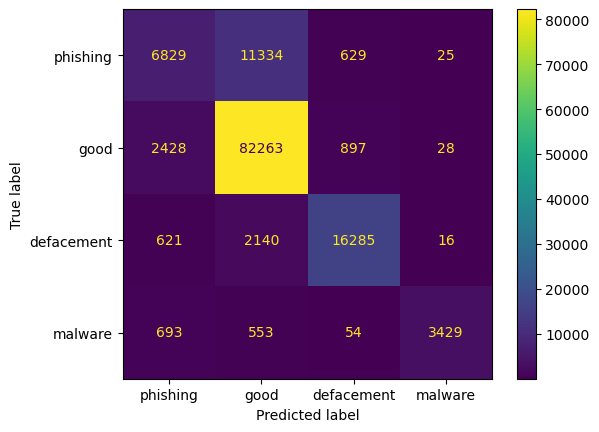

In [ ]:
from sklearn import metrics
import matplotlib.pyplot as plt
import numpy

actual = Y_test
predicted = Y_pred

confusion_matrix = metrics.confusion_matrix(actual, predicted)
label_names = {0: "phishing", 1: "good", 2: "defacement", 3: "malware"}
display_labels = [label_names[c] for c in clf.classes_]

cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = display_labels)

cm_display.plot()
plt.show()